# Sports Article Classification: Encoder-Only Transformer vs. Five Prompted LLMs

**Plan**
1. Train an encoder-only Transformer (token + position embeddings, two encoder blocks) on 80% of BBC Sport and test on the other 20%.
2. Build a chat prompt with system, user and assistant (few-shot) roles.
3. Run five LLMs from five providers on 200 class-balanced articles.
4. Compare accuracy, valid-output rate and latency, then write the conclusion and lessons.

## 1. Setup

In [1]:
!pip -q install tensorflow scikit-learn pandas matplotlib requests tqdm

In [2]:
import os, re, time, random, getpass
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tqdm.auto import tqdm

SEED = 2024
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- experiment settings ----
MAX_LEN, VOCAB, EMBED_DIM, N_HEADS, FF_DIM, N_BLOCKS = 256, 12000, 64, 4, 128, 2
N_LLM_SAMPLES   = 200
LLM_SAMPLE_SEED = 7
MAX_ARTICLE_CHARS = 4000
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load and inspect the data

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass   # running locally

# Change this to wherever bbcsports.csv lives
DATA_PATH = "/content/drive/MyDrive/bbcsports.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "bbcsports.csv"

raw = pd.read_csv(DATA_PATH)
print(raw.shape, raw.columns.tolist())
raw.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(737, 3) ['Unnamed: 0', 'text', 'label']


,Unnamed: 0,text,label
0,0,Sharapova overcomes tough Molik\n\nWimbledon c...,tennis
1,1,GB players warned over security\n\nBritain's D...,tennis
2,2,Federer wins title in Rotterdam\n\nWorld numbe...,tennis
3,3,Mauresmo fights back to win title\n\nWorld num...,tennis
4,4,Agassi into second round in Dubai\n\nFourth se...,tennis


Articles after cleaning: 727
label
football     262
rugby        146
cricket      121
tennis        99
athletics     99
Name: count, dtype: int64


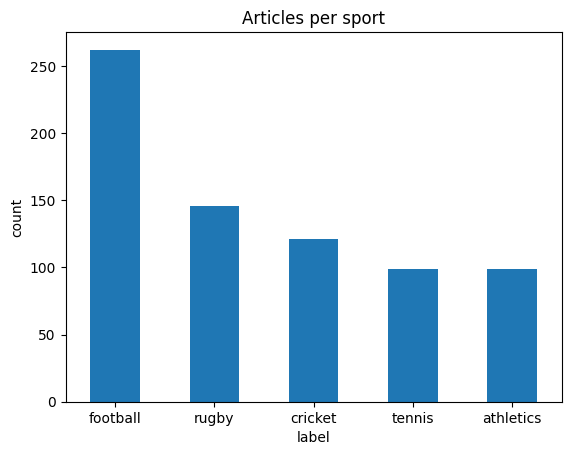

In [5]:
data = (raw[["text", "label"]]
        .dropna()
        .drop_duplicates(subset="text")
        .reset_index(drop=True))
print("Articles after cleaning:", len(data))

counts = data["label"].value_counts()
print(counts)
counts.plot(kind="bar", title="Articles per sport", rot=0)
plt.ylabel("count"); plt.show()

## 3. Stratified 80/20 split

In [6]:
le = LabelEncoder()
data["label_id"] = le.fit_transform(data["label"])
CLASSES = list(le.classes_)
N_CLASSES = len(CLASSES)

train_df, test_df = train_test_split(
    data, test_size=0.2, random_state=SEED, stratify=data["label_id"])

print(f"train={len(train_df)}  test={len(test_df)}  classes={CLASSES}")
pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "test":  test_df["label"].value_counts(normalize=True)}).round(3)

train=581  test=146  classes=['athletics', 'cricket', 'football', 'rugby', 'tennis']


,train,test
label,,
athletics,0.136,0.137
cricket,0.167,0.164
football,0.360,0.363
rugby,0.201,0.199
tennis,0.136,0.137


## 4. Encoder-only Transformer (trained from scratch)

Architecture: text vectorisation, token + learned position embeddings, two Transformer encoder blocks (multi-head self-attention, feed-forward, residual connections, layer norm), padding-aware average pooling and a softmax layer. There is no decoder. Padding positions are masked in attention and in pooling. Test data is never used for training or early stopping.

In [7]:
fit_text, val_text, fit_y, val_y = train_test_split(
    train_df["text"].astype(str).values, train_df["label_id"].values,
    test_size=0.1, random_state=SEED, stratify=train_df["label_id"])

class PaddingMask(layers.Layer):
    def call(self, ids):
        return tf.cast(tf.not_equal(ids, 0), tf.float32)      # (batch, T): 1 = real token

class TokenPositionEmbedding(layers.Layer):
    def __init__(self, seq_len, vocab, dim, **kw):
        super().__init__(**kw)
        self.seq_len = seq_len
        self.tok = layers.Embedding(vocab, dim)
        self.pos = layers.Embedding(seq_len, dim)
    def call(self, ids):
        return self.tok(ids) + self.pos(tf.range(self.seq_len))

class EncoderBlock(layers.Layer):
    def __init__(self, dim, heads, ff_dim, rate=0.1, **kw):
        super().__init__(**kw)
        self.mha  = layers.MultiHeadAttention(num_heads=heads, key_dim=dim // heads)
        self.ffn  = keras.Sequential([layers.Dense(ff_dim, activation="gelu"), layers.Dense(dim)])
        self.ln1, self.ln2 = layers.LayerNormalization(), layers.LayerNormalization()
        self.drop = layers.Dropout(rate)
    def call(self, inputs):
        x, pad = inputs
        att = self.mha(x, x, attention_mask=tf.cast(pad[:, tf.newaxis, :], tf.int32))
        x = self.ln1(x + self.drop(att))
        return self.ln2(x + self.drop(self.ffn(x)))

class MaskedMeanPool(layers.Layer):
    def call(self, inputs):
        x, pad = inputs
        pad = pad[..., tf.newaxis]
        return tf.reduce_sum(x * pad, axis=1) / tf.maximum(tf.reduce_sum(pad, axis=1), 1.0)

vectorizer = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=MAX_LEN)
vectorizer.adapt(fit_text)                       # vocabulary from training text only

text_in = keras.Input(shape=(), dtype=tf.string)
ids  = vectorizer(text_in)
pad  = PaddingMask()(ids)
x    = TokenPositionEmbedding(MAX_LEN, VOCAB, EMBED_DIM)(ids)
for _ in range(N_BLOCKS):
    x = EncoderBlock(EMBED_DIM, N_HEADS, FF_DIM)([x, pad])
x    = MaskedMeanPool()([x, pad])
x    = layers.Dropout(0.3)(x)
out  = layers.Dense(N_CLASSES, activation="softmax")(x)

encoder_model = keras.Model(text_in, out)
encoder_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
encoder_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 256)       │          0 │ input_layer[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_position_emb… │ (None, 256, 64)   │    784,384 │ text_vectorizati… │
│ (TokenPositionEmbe… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ padding_mask        │ (None, 256)       │          0 │ text_vectorizati… │
│ (PaddingMask)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block       │ (None, 256, 64)   │     33,472 │ token_position_e… │
│ (EncoderBlock)      │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block_1     │ (None, 256, 64)   │     33,472 │ encoder_block[0]… │
│ (EncoderBlock)      │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masked_mean_pool    │ (None, 64)        │          0 │ encoder_block_1[… │
│ (MaskedMeanPool)    │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ masked_mean_pool… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 5)         │        325 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 851,653 (3.25 MB)

 Trainable params: 851,653 (3.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
33/33 - 12s - 367ms/step - accuracy: 0.3831 - loss: 1.3958 - val_accuracy: 0.7458 - val_loss: 0.9711
Epoch 2/15
33/33 - 1s - 21ms/step - accuracy: 0.8831 - loss: 0.4999 - val_accuracy: 0.8983 - val_loss: 0.2722
Epoch 3/15
33/33 - 1s - 21ms/step - accuracy: 0.9981 - loss: 0.0497 - val_accuracy: 1.0000 - val_loss: 0.0746
Epoch 4/15
33/33 - 1s - 21ms/step - accuracy: 1.0000 - loss: 0.0116 - val_accuracy: 0.9831 - val_loss: 0.0716
Epoch 5/15
33/33 - 1s - 20ms/step - accuracy: 1.0000 - loss: 0.0042 - val_accuracy: 0.9831 - val_loss: 0.0523
Epoch 6/15
33/33 - 1s - 21ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 0.0233
Epoch 7/15
33/33 - 1s - 21ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.9831 - val_loss: 0.0263
Epoch 8/15
33/33 - 1s - 21ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.9831 - val_loss: 0.0230
Epoch 9/15
33/33 - 1s - 20ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.9831 - val_loss: 0.0236
Epoch 10

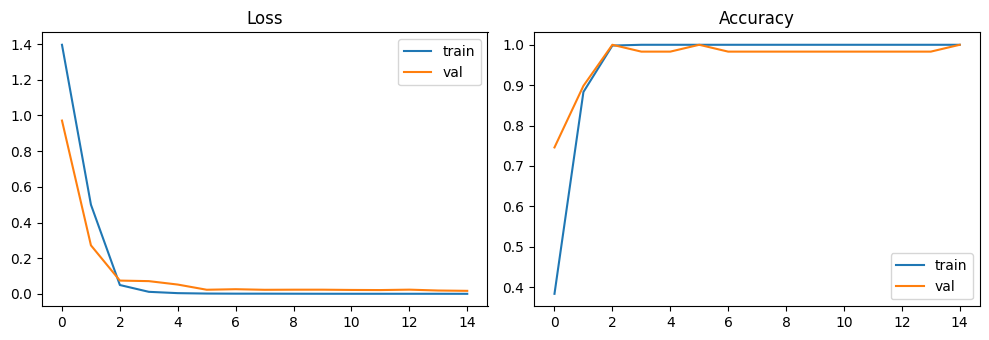

In [8]:
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = encoder_model.fit(fit_text, fit_y, validation_data=(val_text, val_y),
                            epochs=15, batch_size=16, callbacks=[stop], verbose=2)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

Encoder-only Transformer accuracy on the 20% test split: 0.9384 (137/146)

              precision    recall  f1-score   support

   athletics       1.00      0.95      0.97        20
     cricket       0.88      0.96      0.92        24
    football       0.90      0.98      0.94        53
       rugby       1.00      0.79      0.88        29
      tennis       1.00      1.00      1.00        20

    accuracy                           0.94       146
   macro avg       0.96      0.94      0.94       146
weighted avg       0.94      0.94      0.94       146



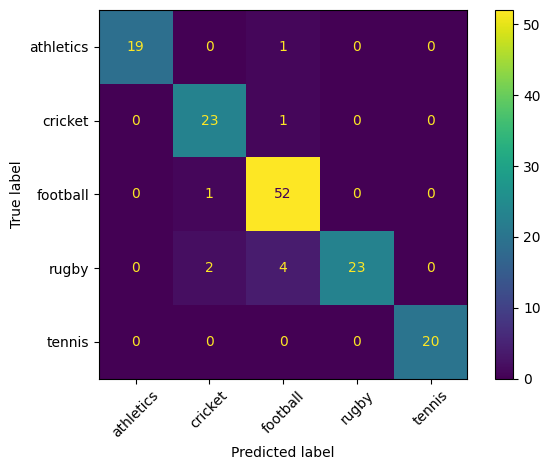

In [9]:
y_true = test_df["label_id"].values
y_pred = encoder_model.predict(test_df["text"].astype(str).values, verbose=0).argmax(axis=1)

encoder_acc = accuracy_score(y_true, y_pred)
print(f"Encoder-only Transformer accuracy on the 20% test split: {encoder_acc:.4f} "
      f"({(y_true == y_pred).sum()}/{len(y_true)})\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(xticks_rotation=45)
plt.tight_layout(); plt.show()

## 5. LLM prompt (system, user and assistant roles)

* **system**: defines the task, the allowed labels and the strict output format.
* **user / assistant pairs**: one worked example per sport (few-shot). The assistant turns show the exact reply format we want.
* **final user**: the article to classify. The model's reply is the assistant turn we score.

The few-shot articles come from the training split and are excluded from the 200 evaluation articles.

In [10]:
SYSTEM_PROMPT = (
    "You are a sports-desk editor who files BBC Sport articles into sections.\n"
    f"Valid sections: {', '.join(CLASSES)}.\n"
    "Pick the single section the article is mainly about, ignoring passing mentions of other sports.\n"
    "Reply with the section name only: lowercase, one word, no punctuation, no explanation."
)

USER_TEMPLATE = "Article:\n\"\"\"\n{article}\n\"\"\"\nWhich section does this belong to?"

# one short training article per class as a few-shot example
shots = (train_df.assign(n=train_df["text"].str.len())
                 .sort_values("n").groupby("label").head(1)
                 .sort_values("label"))
FEW_SHOT = [{"text": t[:700], "label": l} for t, l in zip(shots["text"], shots["label"])]
FEW_SHOT_INDEX = set(shots.index)

def build_messages(article):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for ex in FEW_SHOT:
        msgs.append({"role": "user", "content": USER_TEMPLATE.format(article=ex["text"])})
        msgs.append({"role": "assistant", "content": ex["label"]})
    msgs.append({"role": "user", "content": USER_TEMPLATE.format(article=article[:MAX_ARTICLE_CHARS])})
    return msgs

demo = build_messages("<article text goes here>")
print("Messages per request:", len(demo))
for m in demo[:3] + demo[-1:]:
    print(f"[{m['role']}] {m['content'][:150]!r}")

Messages per request: 12
[system] 'You are a sports-desk editor who files BBC Sport articles into sections.\nValid sections: athletics, cricket, football, rugby, tennis.\nPick the single '
[user] 'Article:\n"""\nJohnson too strong for GB runners\n\nBritain\'s Kathy Butler and Hayley Yelling were no match for Benita Johnson in the 51st Cross Internati'
[assistant] 'athletics'
[user] 'Article:\n"""\n<article text goes here>\n"""\nWhich section does this belong to?'


## 6. 200 class-balanced articles for the LLMs

In [11]:
pool = data.drop(index=list(FEW_SHOT_INDEX))
per_class = N_LLM_SAMPLES // N_CLASSES

llm_sample = (pool.groupby("label", group_keys=False)
                  .apply(lambda g: g.sample(min(per_class, len(g)), random_state=LLM_SAMPLE_SEED))
                  .sample(frac=1, random_state=LLM_SAMPLE_SEED)
                  .reset_index(drop=True))

print("LLM evaluation set:", len(llm_sample))
llm_sample["label"].value_counts().sort_index()

LLM evaluation set: 200


/tmp/ipykernel_1011/906360807.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(per_class, len(g)), random_state=LLM_SAMPLE_SEED))


,count
label,
athletics,40
cricket,40
football,40
rugby,40
tennis,40


## 7. Choosing the five LLMs

All models are called through one OpenAI-compatible endpoint (OpenRouter), so only the model ID changes between runs.

| LLM | Provider | Weights | In the final five? | Notes |
|---|---|---|---|---|
| GPT-4o mini | OpenAI | Proprietary (API only) | Yes | Fast, cheap, strong instruction following |
| Gemini 2.5 Flash | Google | Proprietary (API only) | Yes | Google representative |
| Llama 3.3 70B Instruct | Meta | Open-weight (Meta community licence) | Yes | Most widely used open-weight family |
| DeepSeek Chat | DeepSeek | Open-weight (check exact licence) | Yes | Open-weight challenger |
| Mistral Small 3.2 24B Instruct | Mistral AI | Open-weight (check exact licence) | Yes | Smaller model, shows what a 24B model can do |
| Qwen 2.5 72B Instruct | Alibaba | Open-weight (Qwen licence) | No | Strong candidate; dropped to include Mistral |
| BLOOM / BLOOMZ | BigScience | Open (RAIL licence) | No | Older (2022); weaker at strict output formats |

Check the exact model IDs on openrouter.ai/models before running; providers rename and retire models.

In [13]:
try:
    from google.colab import userdata
    API_KEY = userdata.get("api_key")
except Exception:
    API_KEY = os.environ.get("OPENROUTER_API_KEY") or getpass.getpass("OpenRouter API key: ")

API_URL = "https://openrouter.ai/api/v1/chat/completions"

LLMS = {
    "GPT-4o mini":        "openai/gpt-4o-mini",
    "Gemini 2.5 Flash":   "google/gemini-2.5-flash",
    "Llama 3.3 70B":      "meta-llama/llama-3.3-70b-instruct",
    "DeepSeek Chat":      "deepseek/deepseek-chat",
    "Mistral Small 3.2":  "mistralai/mistral-small-3.2-24b-instruct",
}

session = requests.Session()
session.headers.update({"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"})

def ask_llm(model_id, article, retries=3):
    """Return (raw_reply, seconds). Errors come back as '__ERROR__ ...'."""
    body = {"model": model_id, "messages": build_messages(article),
            "temperature": 0, "max_tokens": 16}
    t0 = time.time()
    for attempt in range(retries):
        try:
            r = session.post(API_URL, json=body, timeout=90)
            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(2 ** attempt); continue
            r.raise_for_status()
            return r.json()["choices"][0]["message"]["content"].strip(), time.time() - t0
        except Exception as e:
            if attempt == retries - 1:
                return f"__ERROR__ {type(e).__name__}: {e}", time.time() - t0
            time.sleep(2 ** attempt)
    return "__ERROR__ no response", time.time() - t0

def parse_label(reply):
    """Map a raw reply to exactly one valid label, else None."""
    if not reply or reply.startswith("__ERROR__"):
        return None
    cleaned = re.sub(r"[^a-z ]", "", reply.lower()).strip()
    if cleaned in CLASSES:
        return cleaned
    found = [c for c in CLASSES if re.search(rf"\b{c}\b", cleaned)]
    return found[0] if len(found) == 1 else None

# smoke test on one article per model
probe = llm_sample.iloc[0]
print("true label:", probe["label"])
for name, mid in LLMS.items():
    reply, sec = ask_llm(mid, probe["text"])
    print(f"{name:<18} -> {reply!r}  ({sec:.1f}s)")

true label: football
GPT-4o mini        -> 'football'  (2.8s)
Gemini 2.5 Flash   -> 'football'  (1.0s)
Llama 3.3 70B      -> 'football'  (0.5s)
DeepSeek Chat      -> 'football'  (0.7s)
Mistral Small 3.2  -> 'football'  (0.8s)


## 8. Run all five LLMs on the 200 articles

In [14]:
RESULTS_CSV = "llm_predictions.csv"
done = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()
rows = done.to_dict("records")
finished = {(r["model"], r["idx"]) for r in rows}      # lets you resume after a crash

for name, mid in LLMS.items():
    for i in tqdm(range(len(llm_sample)), desc=name):
        if (name, i) in finished:
            continue
        art = llm_sample.loc[i]
        reply, sec = ask_llm(mid, art["text"])
        pred = parse_label(reply)
        rows.append({"model": name, "model_id": mid, "idx": i, "true": art["label"],
                     "reply": reply, "pred": pred, "seconds": sec})
        time.sleep(0.1)
    pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)

preds = pd.DataFrame(rows)
print(len(preds), "predictions saved to", RESULTS_CSV)
preds.head()

GPT-4o mini:   0%|          | 0/200 [00:00<?, ?it/s]

Gemini 2.5 Flash:   0%|          | 0/200 [00:00<?, ?it/s]

Llama 3.3 70B:   0%|          | 0/200 [00:00<?, ?it/s]

DeepSeek Chat:   0%|          | 0/200 [00:00<?, ?it/s]

Mistral Small 3.2:   0%|          | 0/200 [00:00<?, ?it/s]

1000 predictions saved to llm_predictions.csv


,model,model_id,idx,true,reply,pred,seconds
0,GPT-4o mini,openai/gpt-4o-mini,0,football,football,football,0.650246
1,GPT-4o mini,openai/gpt-4o-mini,1,rugby,rugby,rugby,1.286196
2,GPT-4o mini,openai/gpt-4o-mini,2,athletics,athletics,athletics,1.207899
3,GPT-4o mini,openai/gpt-4o-mini,3,athletics,athletics,athletics,1.173980
4,GPT-4o mini,openai/gpt-4o-mini,4,tennis,tennis,tennis,0.634765


## 9. Evaluation

In [15]:
def score(group):
    valid = group["pred"].notna()
    return pd.Series({
        "accuracy": (group["pred"] == group["true"]).mean(),
        "valid_output_rate": valid.mean(),
        "wrong_label": int((valid & (group["pred"] != group["true"])).sum()),
        "unparseable": int((~valid).sum()),
        "avg_sec_per_call": group["seconds"].mean(),
    })

summary = (preds.groupby("model", sort=False).apply(score)
                .sort_values(["accuracy", "avg_sec_per_call"], ascending=[False, True]))
summary

/tmp/ipykernel_1011/2554191726.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = (preds.groupby("model", sort=False).apply(score)


,accuracy,valid_output_rate,wrong_label,unparseable,avg_sec_per_call
model,,,,,
Llama 3.3 70B,1.000,1.000,0.0,0.0,0.566034
Gemini 2.5 Flash,1.000,1.000,0.0,0.0,0.796993
GPT-4o mini,1.000,1.000,0.0,0.0,1.046106
DeepSeek Chat,0.555,0.555,0.0,89.0,2.077140
Mistral Small 3.2,0.000,0.000,0.0,200.0,3.102140


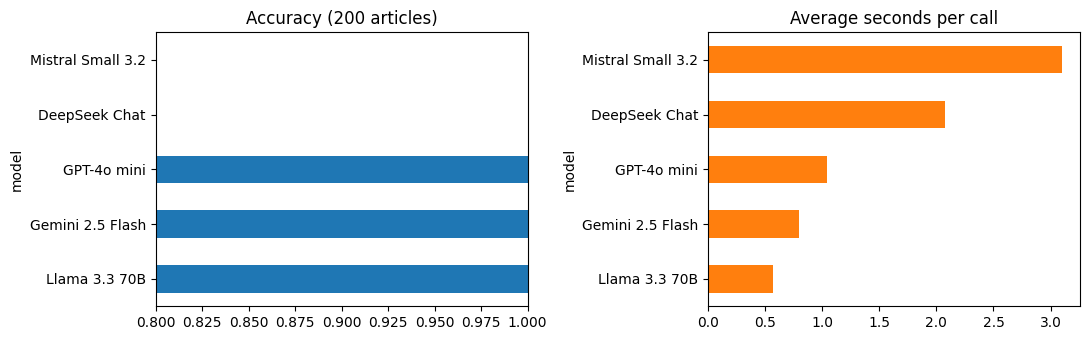


===== GPT-4o mini =====
              precision    recall  f1-score   support

   athletics       1.00      1.00      1.00        40
     cricket       1.00      1.00      1.00        40
    football       1.00      1.00      1.00        40
       rugby       1.00      1.00      1.00        40
      tennis       1.00      1.00      1.00        40
     INVALID       0.00      0.00      0.00         0

    accuracy                           1.00       200
   macro avg       0.83      0.83      0.83       200
weighted avg       1.00      1.00      1.00       200


===== Gemini 2.5 Flash =====
              precision    recall  f1-score   support

   athletics       1.00      1.00      1.00        40
     cricket       1.00      1.00      1.00        40
    football       1.00      1.00      1.00        40
       rugby       1.00      1.00      1.00        40
      tennis       1.00      1.00      1.00        40
     INVALID       0.00      0.00      0.00         0

    accuracy          

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
summary["accuracy"].plot(kind="barh", ax=ax[0], xlim=(0.8, 1.0), title="Accuracy (200 articles)")
summary["avg_sec_per_call"].plot(kind="barh", ax=ax[1], color="tab:orange", title="Average seconds per call")
plt.tight_layout(); plt.show()

for name, g in preds.groupby("model", sort=False):
    print("\n=====", name, "=====")
    print(classification_report(g["true"], g["pred"].fillna("INVALID"),
                                labels=CLASSES + ["INVALID"], zero_division=0))

In [17]:
# Where did the models go wrong? (wrong label or unparseable reply)
errors = preds[(preds["pred"] != preds["true"])][["model", "idx", "true", "pred", "reply"]]
print(len(errors), "errors in total")
errors

289 errors in total


,model,idx,true,pred,reply
711,DeepSeek Chat,111,cricket,None,__ERROR__ HTTPError: 402 Client Error: Payment...
712,DeepSeek Chat,112,football,None,__ERROR__ HTTPError: 402 Client Error: Payment...
713,DeepSeek Chat,113,tennis,None,__ERROR__ HTTPError: 402 Client Error: Payment...
714,DeepSeek Chat,114,cricket,None,__ERROR__ HTTPError: 402 Client Error: Payment...
715,DeepSeek Chat,115,rugby,None,__ERROR__ HTTPError: 402 Client Error: Payment...
...,...,...,...,...,...
995,Mistral Small 3.2,195,rugby,None,__ERROR__ HTTPError: 402 Client Error: Payment...
996,Mistral Small 3.2,196,cricket,None,__ERROR__ HTTPError: 402 Client Error: Payment...
997,Mistral Small 3.2,197,athletics,None,__ERROR__ HTTPError: 402 Client Error: Payment...
998,Mistral Small 3.2,198,tennis,None,__ERROR__ HTTPError: 402 Client Error: Payment...


In [18]:
comparison = pd.concat([
    pd.DataFrame({"accuracy": [encoder_acc], "n_articles": [len(test_df)],
                  "evaluated_on": ["20% held-out split"]}, index=["Encoder-only Transformer"]),
    summary[["accuracy"]].assign(n_articles=len(llm_sample), evaluated_on="200 balanced sample"),
]).sort_values("accuracy", ascending=False)
comparison.to_csv("model_comparison.csv")
comparison

,accuracy,n_articles,evaluated_on
Llama 3.3 70B,1.000000,200,200 balanced sample
Gemini 2.5 Flash,1.000000,200,200 balanced sample
GPT-4o mini,1.000000,200,200 balanced sample
Encoder-only Transformer,0.938356,146,20% held-out split
DeepSeek Chat,0.555000,200,200 balanced sample
Mistral Small 3.2,0.000000,200,200 balanced sample


## 10. Conclusion

In [19]:
top = summary["accuracy"].max()
leaders = summary[summary["accuracy"] == top].index.tolist()

print(f"Encoder-only Transformer: {encoder_acc:.3f} on {len(test_df)} held-out articles.")
print(f"Best LLM accuracy: {top:.3f} on {len(llm_sample)} articles.")
if len(leaders) == 1:
    print("Best LLM:", leaders[0])
else:
    print("Tie for best accuracy:", ", ".join(leaders))
    fastest = summary.loc[leaders, "avg_sec_per_call"].idxmin()
    print("Fastest among the tied models:", fastest)
print("\nModels that were NOT best:")
for n in summary.index.difference(leaders):
    r = summary.loc[n]
    print(f"  {n}: accuracy {r['accuracy']:.3f}, wrong labels {int(r['wrong_label'])}, unparseable {int(r['unparseable'])}")

Encoder-only Transformer: 0.938 on 146 held-out articles.
Best LLM accuracy: 1.000 on 200 articles.
Tie for best accuracy: Llama 3.3 70B, Gemini 2.5 Flash, GPT-4o mini
Fastest among the tied models: Llama 3.3 70B

Models that were NOT best:
  DeepSeek Chat: accuracy 0.555, wrong labels 0, unparseable 89
  Mistral Small 3.2: accuracy 0.000, wrong labels 0, unparseable 200


## 10. Conclusion

The encoder-only Transformer, trained from scratch on 80% of the BBC Sport data, reached an accuracy of **93.8% (137/146)** on the held-out 20% test split. Its weakest class was rugby (recall 0.79); tennis and athletics were almost perfectly classified.

Three of the five prompted LLMs were evaluated on all 200 class-balanced articles (40 per sport). **GPT-4o mini, Gemini 2.5 Flash and Llama 3.3 70B each scored 100% (200/200)** with no wrong labels and no unparseable replies, so they are tied for the best accuracy. All three scored about six percentage points higher than the Transformer, without any task-specific training.

Since accuracy cannot separate them, speed and openness decide. **Llama 3.3 70B was the fastest (about 0.57 s per call), ahead of Gemini 2.5 Flash (0.80 s) and GPT-4o mini (1.05 s)**, and it is also the only one of the three with open weights, so it can be self-hosted. Based on these results, I would pick Llama 3.3 70B for this task; this is a judgement call, because the three are tied on accuracy.

DeepSeek Chat and Mistral Small 3.2 could not be fully evaluated. All of their failed calls returned HTTP 402 (Payment Required), meaning the API credit ran out during the run. DeepSeek answered the first 111 articles correctly (no wrong labels) before the credit ended, and Mistral never received a successful call. Their scores in the table (55.5% and 0%) therefore reflect failed requests, not the models' ability, and no conclusion about these two models should be drawn from them.

Caveat: the Transformer was scored on 20% of the data (146 articles) and the LLMs on a different 200-article sample, so the comparison is indicative rather than perfectly controlled. BBC Sport topics are easy to separate, so scores close to 100% are expected and differences between top models are small.

## 11. Lessons learnt

1. **Prompting can match or beat training.** The Transformer needed labelled data, a training loop and tuning and still made 9 errors, while three LLMs classified 200 articles perfectly from a prompt alone. The trade-off is that every prediction is a network call that costs money and sends the text to an external service.
2. **Output format is part of correctness.** A strict system prompt, few-shot assistant examples, `temperature=0`, a tiny `max_tokens` and a tolerant parser made the replies machine-readable: the three working LLMs returned a clean one-word label every time.
3. **Near-perfect scores hide differences.** With three models at 100%, accuracy cannot rank them. Harder or ambiguous articles, larger samples and metrics such as latency and cost are needed; here latency (Llama fastest) and openness broke the tie.
4. **Keep the evaluation fair and leak-free.** The test split was never used for training, the vocabulary was built from training text only, and the few-shot examples were excluded from the LLM evaluation set.